## Experiment: descriptive statistics before hypothesis testing.

In [1]:
import pandas as pd
import numpy as np

url = (
    "https://userpage.fu-berlin.de/"
    "soga/data/raw-data/students.csv"
)

students = pd.read_csv(url)

# Remove missing weights before drawing the sample.
weights = students["weight"].dropna()

sample = weights.sample(
    n=14,
    random_state=8
)

mu_0 = 70.8

sample_mean = sample.mean()
sample_sd = sample.std(ddof=1)
difference = sample_mean - mu_0

print(f"Sample size: {len(sample)}")
print(f"Sample mean: {sample_mean:.2f} kg")
print(f"Sample SD: {sample_sd:.2f} kg")
print(f"Difference from benchmark: {difference:.2f} kg")

# The sample mean is an estimate of the population mean.
# A difference alone is not a hypothesis-test decision.

Sample size: 14
Sample mean: 69.82 kg
Sample SD: 5.80 kg
Difference from benchmark: -0.98 kg


## Experiment: formulating hypotheses for an A/B test.

In [2]:
import numpy as np

rng = np.random.default_rng(2026)

# Simulated independent user-level conversions.
n_a = 1000
n_b = 1000

conversions_a = rng.binomial(
    n=1, p=0.10, size=n_a
)

conversions_b = rng.binomial(
    n=1, p=0.12, size=n_b
)

rate_a = np.mean(conversions_a)
rate_b = np.mean(conversions_b)

estimated_difference = rate_b - rate_a

print(f"Version A conversion rate: {rate_a:.2%}")
print(f"Version B conversion rate: {rate_b:.2%}")

print(
    "Estimated difference: "
    f"{100 * estimated_difference:.2f} percentage points"
)

# Hypotheses:
# H0: p_B - p_A = 0
# H1: p_B - p_A != 0

# The observed difference is not itself
# sufficient for deciding whether to reject H0.

Version A conversion rate: 11.40%
Version B conversion rate: 11.70%
Estimated difference: 0.30 percentage points


## Experiment: sampling variability under a true null hypothesis.

Mean of simulated sample means: 100.02
SD of simulated sample means: 1.991
Theoretical standard error: 2.0


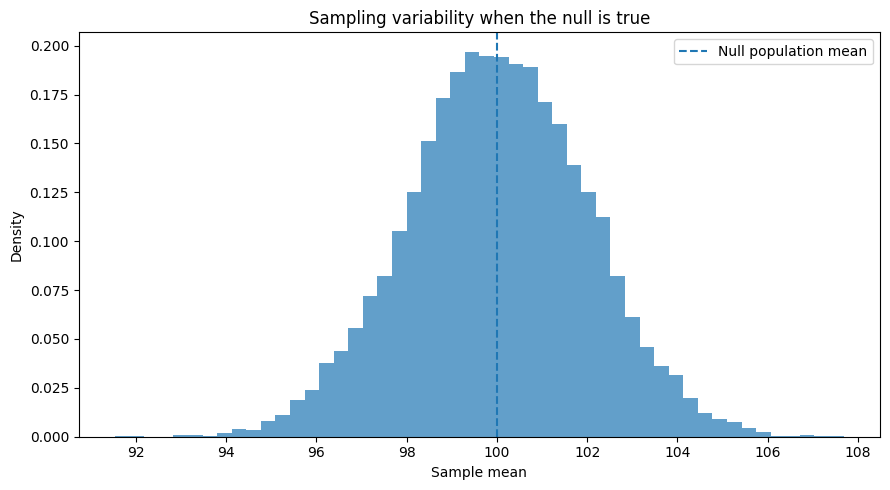

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

mu_0 = 100
sigma = 10
n = 25
repetitions = 10_000

# Each row represents an independent study.
samples = rng.normal(
    loc=mu_0,
    scale=sigma,
    size=(repetitions, n)
)

sample_means = samples.mean(axis=1)

print(
    "Mean of simulated sample means:",
    round(np.mean(sample_means), 3)
)

print(
    "SD of simulated sample means:",
    round(np.std(sample_means, ddof=1), 3)
)

print(
    "Theoretical standard error:",
    round(sigma / np.sqrt(n), 3)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    sample_means,
    bins=50,
    density=True,
    alpha=0.7
)

ax.axvline(
    mu_0,
    linestyle="--",
    label="Null population mean"
)

ax.set_xlabel("Sample mean")
ax.set_ylabel("Density")
ax.set_title(
    "Sampling variability when the null is true"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    "../../images/hypothesis_sampling_variability.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# Experiment: repeat with n = 100 and n = 400.
# Compare the variability of the sample means.